# ShopSegments: customer segmentation and product recommender

One notebook that runs the whole pipeline on the Online Retail transactions:

1. Load and clean the transactions.
2. Quick EDA and RFM features.
3. Train a K-Means customer segmentation model (k chosen by metrics and business sense).
4. Train and tune recommenders (Popularity, item-based CF, ALS, hybrid) with a leak-free temporal hold-out.
5. Retrain the chosen models on all data, export the artifacts and **save the trained models**.

**Standalone notebook.** This is the self-contained Colab version of the pipeline: it deliberately does not import `src/shopsegments`, so it runs on its own after uploading one CSV. It mirrors `src/` and `scripts/build_artifacts.py` (same cleaning rules, RFM features, k, seeds and split dates) and gives the same numbers as `artifacts/metrics.json`; the last cell of this notebook checks that.

**Google Colab:** upload your CSV so it lives at `/content/dataset.csv`, then run all cells. Both *Online Retail* and *Online Retail II* work (columns are renamed automatically). The hold-out split dates are computed from the dates in your file, so the notebook also runs on a partial file, but the full file (to 2011-12-09) gives the most meaningful results.


In [1]:
# Colab already has most packages; `implicit` (ALS) is the one that is usually missing.
%pip install -q implicit


error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.


    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detailed specification.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
from pathlib import Path
import json

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, normalize
from implicit.cpu.als import AlternatingLeastSquares

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
TOP_K = 10
RECO_SPLIT_DATE = None                    # set automatically after loading (last ~3 months = test window)
RECO_VAL_SPLIT_DATE = None                # set automatically (the ~3 months before = validation window)
N_SEGMENTS = 5

DATA_CSV = Path("/content/dataset.csv")   # Colab: upload your CSV with this name
if not DATA_CSV.exists():                 # local run: use the file from scripts/download_data.py
    for cand in (Path("../data/raw/online_retail.csv"), Path("data/raw/online_retail.csv")):
        if cand.exists():
            DATA_CSV = cand; break
START_DATE = "2010-12-01"                 # Online Retail II starts in Dec 2009; keep the 2010-12 -> 2011-12 window
OUT = Path("shopsegments_outputs")
OUT.mkdir(exist_ok=True)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the data

In [3]:
COLUMN_ALIASES = {            # Online Retail II uses different column names
    "Invoice": "InvoiceNo", "Price": "UnitPrice", "Customer ID": "CustomerID",
}

def load_raw_csv(path: Path = DATA_CSV) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Upload your CSV in Colab (Files panel) and name it dataset.csv")
    df = pd.read_csv(path, dtype={"Invoice": str, "InvoiceNo": str, "StockCode": str,
                                  "Description": str, "Country": str}, encoding="utf-8")
    df = df.rename(columns=COLUMN_ALIASES)
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="mixed", errors="coerce")
    df = df.dropna(subset=["InvoiceDate", "InvoiceNo", "StockCode"])          # drop truncated / broken rows
    print(f"File covers {df['InvoiceDate'].min()} -> {df['InvoiceDate'].max()} ({len(df):,} rows)")
    filtered = df[df["InvoiceDate"] >= START_DATE]
    if filtered.empty:                                                          # partial file: use all of it
        print(f"Note: no rows on/after {START_DATE}; using the whole file.")
        return df.reset_index(drop=True)
    return filtered.reset_index(drop=True)

raw = load_raw_csv()

# Hold-out windows computed from the data: test = last ~91 days, validation = the ~92 days before.
t_min, t_max = raw["InvoiceDate"].min().normalize(), raw["InvoiceDate"].max().normalize()
span_days = (t_max - t_min).days
test_days = int(min(91, span_days * 0.25))
val_days = int(min(92, span_days * 0.25))
RECO_SPLIT_DATE = str((t_max - pd.Timedelta(days=test_days)).date())
RECO_VAL_SPLIT_DATE = str((pd.Timestamp(RECO_SPLIT_DATE) - pd.Timedelta(days=val_days)).date())
print(f"Rows: {len(raw):,} | span: {span_days} days")
print(f"Recommender split -> validation from {RECO_VAL_SPLIT_DATE}, test from {RECO_SPLIT_DATE}")
if span_days < 300:
    print("WARNING: the file covers less than a year. It runs, but for the full results upload the complete "
          "online_retail_II.csv (about 1.07M rows, up to 2011-12-09).")
raw.head()


File covers 2010-12-01 08:26:00 -> 2011-12-09 12:50:00 (541,909 rows)
Rows: 541,909 | span: 373 days
Recommender split -> validation from 2011-06-09, test from 2011-09-09


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Clean the transactions

In [4]:
# Real products have a 5-digit stock code, sometimes with a letter suffix (85123A).
# Everything else is postage, fees, adjustments, vouchers and similar.
PRODUCT_CODE_PATTERN = r"^\d{5}[A-Za-z]{0,2}$"

def clean_transactions(df: pd.DataFrame):
    report = {"raw_rows": len(df)}
    out = df[df["CustomerID"].notna()];                                  report["after_missing_customer"] = len(out)
    out = out[~out["InvoiceNo"].str.startswith("C")];                    report["after_cancellations"] = len(out)
    out = out[(out["Quantity"] > 0) & (out["UnitPrice"] > 0)];           report["after_non_positive"] = len(out)
    out = out[out["StockCode"].str.match(PRODUCT_CODE_PATTERN)];         report["after_non_product_codes"] = len(out)
    out = out.drop_duplicates();                                         report["after_duplicates"] = len(out)

    out = out.assign(StockCode=out["StockCode"].str.upper(),
                     CustomerID=out["CustomerID"].astype(int),
                     Revenue=out["Quantity"] * out["UnitPrice"])
    # One canonical description per product (its most frequent spelling).
    desc = (out.dropna(subset=["Description"]).groupby("StockCode")["Description"]
            .agg(lambda s: s.str.strip().value_counts().index[0]))
    out = out.assign(Description=out["StockCode"].map(desc).fillna(out["StockCode"])).reset_index(drop=True)
    return out, report

tx, report = clean_transactions(raw)
steps = pd.Series(report)
display(pd.DataFrame({"rows": steps, "removed": -steps.diff().fillna(0).astype(int)}))
print(f"Kept {len(tx) / len(raw):.1%} of rows | {tx.CustomerID.nunique():,} customers | "
      f"{tx.StockCode.nunique():,} products | {tx.InvoiceNo.nunique():,} invoices")

,rows,removed
raw_rows,541909,0
after_missing_customer,406829,135080
after_cancellations,397924,8905
after_non_positive,397884,40
after_non_product_codes,396337,1547
after_duplicates,391150,5187


Kept 72.2% of rows | 4,334 customers | 3,659 products | 18,402 invoices


## 3. Quick EDA

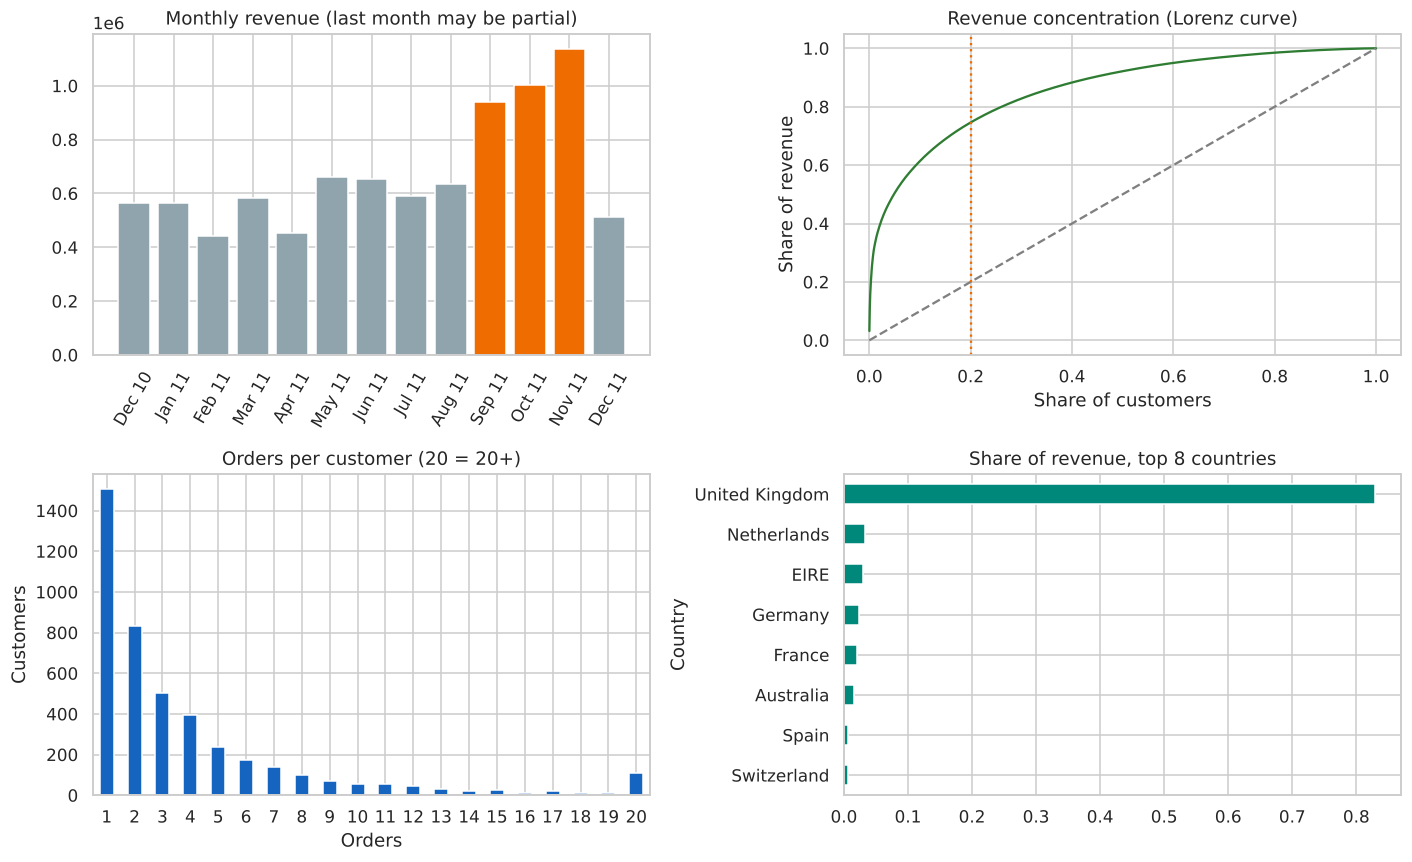

Top 20% of customers = 75% of revenue
One-time buyers: 35% | median orders: 2
UK: 90% of customers, 83% of revenue
Median products per order: 15


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

monthly = tx.set_index("InvoiceDate")["Revenue"].resample("MS").sum()
axes[0, 0].bar([d.strftime("%b %y") for d in monthly.index], monthly.values,
               color=["#EF6C00" if d.month in (9, 10, 11) else "#90A4AE" for d in monthly.index])
axes[0, 0].set_title("Monthly revenue (last month may be partial)")
axes[0, 0].tick_params(axis="x", rotation=60)

cust_rev = tx.groupby("CustomerID")["Revenue"].sum().sort_values(ascending=False)
cum = (cust_rev.cumsum() / cust_rev.sum()).values
x = np.arange(1, len(cum) + 1) / len(cum)
axes[0, 1].plot(x, cum, color="#2E7D32"); axes[0, 1].plot([0, 1], [0, 1], "--", color="grey")
axes[0, 1].axvline(0.2, color="#EF6C00", ls=":"); axes[0, 1].set_title("Revenue concentration (Lorenz curve)")
axes[0, 1].set_xlabel("Share of customers"); axes[0, 1].set_ylabel("Share of revenue")

freq = tx.groupby("CustomerID")["InvoiceNo"].nunique()
freq.clip(upper=20).value_counts().sort_index().plot.bar(ax=axes[1, 0], color="#1565C0", rot=0)
axes[1, 0].set_title("Orders per customer (20 = 20+)"); axes[1, 0].set_xlabel("Orders"); axes[1, 0].set_ylabel("Customers")

cty = tx.groupby("Country").agg(customers=("CustomerID", "nunique"), revenue=("Revenue", "sum"))
(cty["revenue"].sort_values(ascending=False).head(8) / cty["revenue"].sum()).plot.barh(ax=axes[1, 1], color="#00897B")
axes[1, 1].invert_yaxis(); axes[1, 1].set_title("Share of revenue, top 8 countries")

plt.tight_layout(); plt.show()

top20 = cum[int(len(cum) * 0.2) - 1]
uk = cty.loc["United Kingdom"]
print(f"Top 20% of customers = {top20:.0%} of revenue")
print(f"One-time buyers: {(freq == 1).mean():.0%} | median orders: {freq.median():.0f}")
print(f"UK: {uk.customers / cty.customers.sum():.0%} of customers, {uk.revenue / cty.revenue.sum():.0%} of revenue")
print(f"Median products per order: {tx.groupby('InvoiceNo')['StockCode'].nunique().median():.0f}")

## 4. RFM features

Recency is days since the last order, Frequency is the number of distinct invoices and Monetary is total spend. The raw features are heavily skewed, so the model uses `log1p` followed by standardisation.

In [6]:
def build_rfm(transactions: pd.DataFrame) -> pd.DataFrame:
    snapshot = transactions["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
    g = transactions.groupby("CustomerID")
    return pd.DataFrame({
        "Recency": (snapshot - g["InvoiceDate"].max()).dt.days,
        "Frequency": g["InvoiceNo"].nunique(),
        "Monetary": g["Revenue"].sum(),
        "Country": g["Country"].agg(lambda s: s.mode().iloc[0]),
        "FirstPurchase": g["InvoiceDate"].min(),
    })

RFM = ["Recency", "Frequency", "Monetary"]
rfm = build_rfm(tx)
print(f"{len(rfm):,} customers")
display(rfm[RFM].describe().round(1))
print("Skew raw:      ", rfm[RFM].skew().round(1).to_dict())
print("Skew log1p:    ", np.log1p(rfm[RFM]).skew().round(1).to_dict())

4,334 customers


,Recency,Frequency,Monetary
count,4334.0,4334.0,4334.0
mean,92.2,4.2,2016.0
std,100.2,7.6,8903.7
min,0.0,1.0,3.8
25%,17.0,1.0,304.2
50%,50.0,2.0,662.6
75%,142.0,5.0,1631.6
max,373.0,206.0,279138.0


Skew raw:       {'Recency': 1.2, 'Frequency': 11.9, 'Monetary': 19.6}
Skew log1p:     {'Recency': -0.5, 'Frequency': 1.2, 'Monetary': 0.4}


## 5. Segmentation model (K-Means)

The preprocessing is fitted on the RFM table only. The number of clusters is picked from silhouette, Calinski-Harabasz and Davies-Bouldin. Silhouette is almost flat from k = 3 to 6. k = 5 is kept because it separates loyal customers from lapsing ones, and those groups need opposite campaigns.

,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,6481.282,0.434,4358.368,0.891
1,3,4870.934,0.342,3614.888,1.037
2,4,3955.714,0.337,3300.765,1.013
3,5,3325.205,0.316,3149.519,0.996
4,6,2870.609,0.314,3055.014,1.013
5,7,2571.169,0.309,2925.680,0.976
6,8,2357.259,0.300,2790.747,0.997


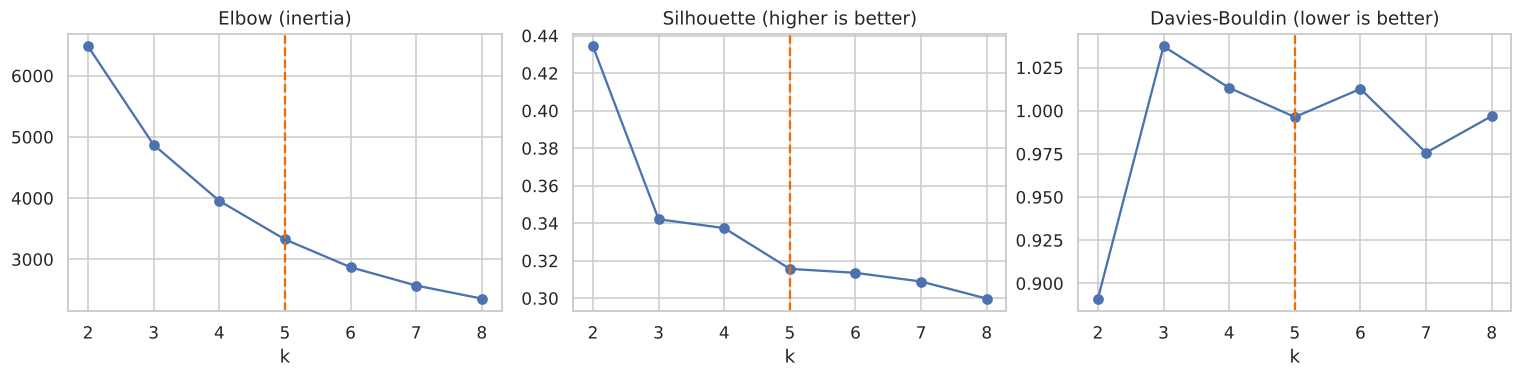

In [7]:
def make_preprocessor() -> Pipeline:
    return Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])

pre = make_preprocessor()
X = pre.fit_transform(rfm[RFM])

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_)})
k_table = pd.DataFrame(rows)
display(k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, col, title in zip(axes, ["inertia", "silhouette", "davies_bouldin"],
                          ["Elbow (inertia)", "Silhouette (higher is better)", "Davies-Bouldin (lower is better)"]):
    ax.plot(k_table["k"], k_table[col], marker="o"); ax.axvline(N_SEGMENTS, ls="--", color="#EF6C00")
    ax.set_title(title); ax.set_xlabel("k")
plt.tight_layout(); plt.show()

In [8]:
# Compare the clustering family on the same features (k = 5).
rows = []
km = KMeans(n_clusters=N_SEGMENTS, n_init=10, random_state=RANDOM_STATE).fit(X)
rows.append(("K-Means", N_SEGMENTS, silhouette_score(X, km.labels_), 0.0))

gl = GaussianMixture(n_components=N_SEGMENTS, covariance_type="full", random_state=RANDOM_STATE).fit(X).predict(X)
rows.append(("Gaussian Mixture", len(np.unique(gl)), silhouette_score(X, gl), 0.0))

for eps in (0.3, 0.5, 0.7):
    lab = DBSCAN(eps=eps, min_samples=15).fit(X).labels_
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    mask = lab != -1
    sil = silhouette_score(X[mask], lab[mask]) if n_clusters > 1 else np.nan
    rows.append((f"DBSCAN eps={eps}", n_clusters, sil, float((lab == -1).mean())))

pd.DataFrame(rows, columns=["model", "n_clusters", "silhouette", "noise_share"]).round(3)

,model,n_clusters,silhouette,noise_share
0,K-Means,5,0.316,0.000
1,Gaussian Mixture,5,0.152,0.000
2,DBSCAN eps=0.3,5,0.129,0.155
3,DBSCAN eps=0.5,2,0.301,0.032
4,DBSCAN eps=0.7,1,NaN,0.010


In [9]:
def name_clusters(rfm_df: pd.DataFrame, labels: np.ndarray) -> dict:
    """Map raw cluster ids to business names from each cluster's median R/F/M.
    Highest Frequency+Monetary rank -> Champions, second -> Loyal. Of the remaining three,
    the least recent -> Lost, the most recent -> New / Promising, the middle one -> At Risk."""
    prof = rfm_df.assign(cluster=labels).groupby("cluster")[RFM].median()
    value = prof["Frequency"].rank() + prof["Monetary"].rank()
    order = value.sort_values(ascending=False).index.tolist()
    if len(prof) != N_SEGMENTS:
        return {c: f"Segment {i + 1}" for i, c in enumerate(order)}
    names = {order[0]: "Champions", order[1]: "Loyal"}
    rest = prof.loc[order[2:]].sort_values("Recency")
    names[rest.index[0]] = "New / Promising"
    names[rest.index[1]] = "At Risk"
    names[rest.index[2]] = "Lost"
    return names

SEGMENT_PLAYBOOK = {
    "Champions": "Reward them: VIP perks, early access, referrals. No discounts.",
    "Loyal": "Cross-sell bundles and loyalty tiers.",
    "New / Promising": "Onboarding series and a second-order incentive.",
    "At Risk": "Personalised win-back now. Highest ROI for reactivation spend.",
    "Lost": "Low-cost channels only. Newsletter or seasonal sale.",
}
SEG_ORDER = list(SEGMENT_PLAYBOOK)
SEG_COLORS = {"Champions": "#2E7D32", "Loyal": "#1565C0", "New / Promising": "#00897B",
              "At Risk": "#EF6C00", "Lost": "#9E9E9E"}

# Final segmentation model: preprocessor + K-Means + cluster-id -> name map.
kmeans = KMeans(n_clusters=N_SEGMENTS, n_init=20, random_state=RANDOM_STATE).fit(X)
seg_model = {"preprocessor": pre, "kmeans": kmeans, "names": name_clusters(rfm, kmeans.labels_)}
print("Cluster names:", seg_model["names"])

def predict_segment(rfm_df: pd.DataFrame, model: dict) -> pd.Series:
    Z = model["preprocessor"].transform(rfm_df[RFM])
    return pd.Series([model["names"][i] for i in model["kmeans"].predict(Z)], index=rfm_df.index, name="Segment")

rfm["Segment"] = predict_segment(rfm, seg_model)
print(f"Silhouette of final model: {silhouette_score(X, kmeans.labels_):.3f}")

Cluster names: {1: 'Champions', 4: 'Loyal', np.int32(3): 'New / Promising', np.int32(0): 'At Risk', np.int32(2): 'Lost'}
Silhouette of final model: 0.316


,customers,median_recency_days,median_orders,median_spend,share_customers,share_revenue,top_products,action
Segment,,,,,,,,
Champions,288,4.0,17.0,6684.285,0.066,0.500,"Jumbo Bag Red Retrospot, Pack Of 72 Retrospot ...","Reward them: VIP perks, early access, referral..."
Loyal,948,16.0,6.0,1955.365,0.219,0.259,"Regency Cakestand 3 Tier, White Hanging Heart ...",Cross-sell bundles and loyalty tiers.
New / Promising,816,21.0,2.0,364.085,0.188,0.039,"Rex Cash+Carry Jumbo Shopper, Paper Chain Kit ...",Onboarding series and a second-order incentive.
At Risk,1052,80.0,3.0,963.520,0.243,0.165,"Regency Cakestand 3 Tier, White Hanging Heart ...",Personalised win-back now. Highest ROI for rea...
Lost,1230,204.0,1.0,236.030,0.284,0.037,"White Hanging Heart T-Light Holder, Regency Ca...",Low-cost channels only. Newsletter or seasonal...


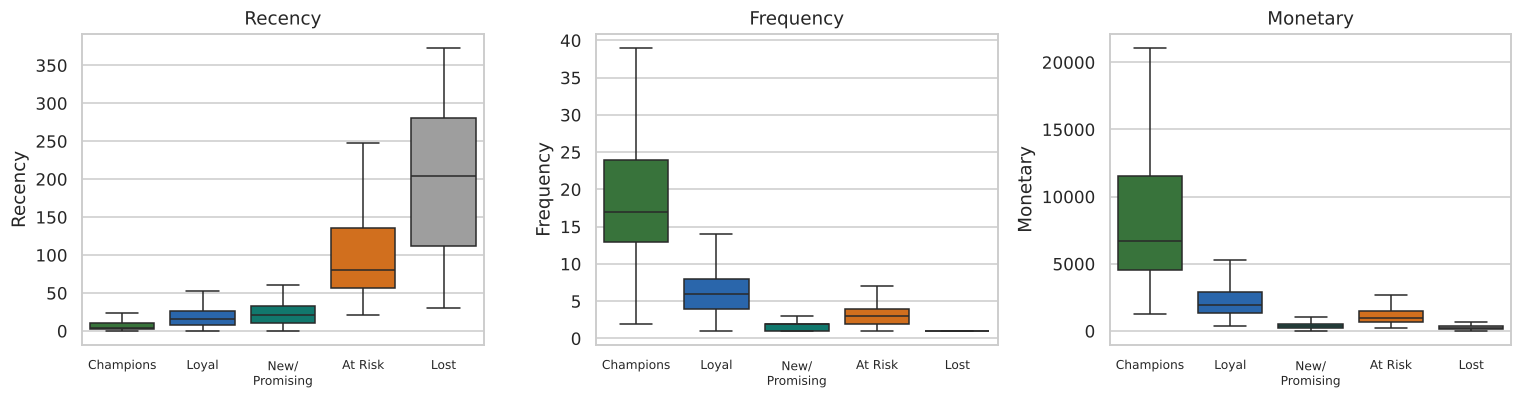

,Recency,Frequency,Monetary,Segment
cust_A,5,12,2500.0,Champions
cust_B,60,3,400.0,At Risk
cust_C,250,1,60.0,Lost


In [10]:
summary = rfm.groupby("Segment").agg(
    customers=("Recency", "size"),
    median_recency_days=("Recency", "median"),
    median_orders=("Frequency", "median"),
    median_spend=("Monetary", "median"),
    revenue=("Monetary", "sum"),
).loc[SEG_ORDER]
summary["share_customers"] = summary["customers"] / summary["customers"].sum()
summary["share_revenue"] = summary["revenue"] / summary["revenue"].sum()
summary = summary.drop(columns="revenue")

seg_tx = tx.merge(rfm[["Segment"]], left_on="CustomerID", right_index=True)
top_products = (seg_tx.groupby(["Segment", "Description"])["CustomerID"].nunique().rename("buyers")
                .reset_index().sort_values(["Segment", "buyers"], ascending=[True, False])
                .groupby("Segment").head(5).groupby("Segment")["Description"].apply(lambda s: ", ".join(s.str.title())))
summary["top_products"] = top_products
summary["action"] = [SEGMENT_PLAYBOOK[s] for s in summary.index]
display(summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, RFM):
    sns.boxplot(data=rfm, x="Segment", y=c, order=SEG_ORDER, hue="Segment", palette=SEG_COLORS,
                legend=False, ax=ax, showfliers=False)
    ax.set_xticks(range(len(SEG_ORDER)))
    ax.set_xticklabels([s.replace(" / ", "/\n") for s in SEG_ORDER], fontsize=8); ax.set_xlabel("")
    ax.set_title(c)
plt.tight_layout(); plt.show()

# Example: segment a new customer from their R / F / M values.
example = pd.DataFrame({"Recency": [5, 60, 250], "Frequency": [12, 3, 1], "Monetary": [2500.0, 400.0, 60.0]},
                       index=["cust_A", "cust_B", "cust_C"])
example["Segment"] = predict_segment(example, seg_model)
example

In [11]:
joblib.dump(seg_model, OUT / "segment_model.joblib")
rfm[RFM + ["Country", "Segment"]].to_csv(OUT / "customer_segments.csv")
summary.to_csv(OUT / "segment_summary.csv")
print("saved:", sorted(p.name for p in OUT.iterdir()))

saved: ['cold_start_top10.json', 'customer_recommendations.csv', 'customer_segments.csv', 'metrics.json', 'recommender_config.joblib', 'recommender_model.joblib', 'segment_model.joblib', 'segment_model.json', 'segment_summary.csv']


## 6. Recommender

**Protocol.** Train on purchases before the test split date (the last ~3 months of the file are the test window). The ground truth for a returning customer is the set of products they bought in the test window but had never bought before, so the metric measures discovery of new products. Hyper-parameters are tuned on a separate validation window (train before the validation split date, validate on the months up to the test split). The test window is used once.

Models:
* **Popularity**: most-bought products. Also the cold-start fallback.
* **Item-based CF**: cosine similarity between products, keeping the top-n neighbours.
* **ALS**: implicit-feedback matrix factorisation (Hu, Koren and Volinsky).
* **Hybrid**: reciprocal rank fusion of Item-CF and ALS.

In [12]:
def build_holdout(transactions: pd.DataFrame, split_date: str):
    split = pd.Timestamp(split_date)
    train = transactions[transactions["InvoiceDate"] < split]
    test = transactions[transactions["InvoiceDate"] >= split]
    train_items = set(train["StockCode"].unique())
    seen = train.groupby("CustomerID")["StockCode"].apply(set)
    bought_after = test.groupby("CustomerID")["StockCode"].apply(set)

    returning, cold = {}, {}
    for u, items in bought_after.items():
        items = items & train_items                  # can't recommend products that did not exist yet
        if u in seen.index:
            new_items = items - seen[u]
            if new_items:
                returning[u] = new_items
        elif items:
            cold[u] = items
    return train, returning, cold

train, truth, cold_truth = build_holdout(tx, RECO_SPLIT_DATE)
print(f"train rows: {len(train):,} | returning test customers: {len(truth):,} | "
      f"brand-new test customers: {len(cold_truth):,}")
print(f"avg new products per returning customer: {np.mean([len(v) for v in truth.values()]):.1f}")

train rows: 231,628 | returning test customers: 1,852 | brand-new test customers: 973
avg new products per returning customer: 30.3


In [13]:
class InteractionData:
    """Customer x product matrix. Value = number of invoices containing the product."""
    def __init__(self, transactions: pd.DataFrame):
        counts = (transactions.groupby(["CustomerID", "StockCode"])["InvoiceNo"].nunique()
                  .rename("n").reset_index())
        self.users = np.sort(counts["CustomerID"].unique())
        self.items = np.sort(counts["StockCode"].unique())
        self.user_index = {u: i for i, u in enumerate(self.users)}
        self.item_index = {it: i for i, it in enumerate(self.items)}
        rows = counts["CustomerID"].map(self.user_index).to_numpy()
        cols = counts["StockCode"].map(self.item_index).to_numpy()
        self.counts = sp.csr_matrix((counts["n"].to_numpy(np.float32), (rows, cols)),
                                    shape=(len(self.users), len(self.items)))
        self.binary = self.counts.copy()
        self.binary.data[:] = 1.0
        self.popularity = np.asarray(self.binary.sum(axis=0)).ravel()

    def seen(self, uidx: int) -> np.ndarray:
        return self.binary[uidx].indices

def top_k_excluding(scores: np.ndarray, exclude: np.ndarray, k: int) -> np.ndarray:
    s = scores.astype(np.float64, copy=True)
    s[exclude] = -np.inf
    idx = np.argpartition(-s, k - 1)[:k]
    idx = idx[np.argsort(-s[idx])]
    return idx[np.isfinite(s[idx])]

class Popularity:
    name = "Popularity"
    desc = ""
    def fit(self, data):
        self.data = data
        return self
    def recommend(self, user_ids, k=TOP_K):
        out = []
        for u in user_ids:
            ui = self.data.user_index.get(u)
            seen = self.data.seen(ui) if ui is not None else np.array([], dtype=int)
            out.append([self.data.items[i] for i in top_k_excluding(self.data.popularity, seen, k)])
        return out

class ItemCF:
    name = "Item-based CF"
    def __init__(self, n_neighbours=20):
        self.n_neighbours = n_neighbours
        self.desc = f"neighbours={n_neighbours}"
    def fit(self, data):
        self.data = data
        vecs = normalize(data.binary.T.tocsr(), norm="l2", axis=1)
        sim = (vecs @ vecs.T).toarray().astype(np.float32)
        np.fill_diagonal(sim, 0.0)
        n = self.n_neighbours
        if n and n < sim.shape[0]:                    # keep only the strongest neighbours per product
            thr = -np.partition(-sim, n - 1, axis=1)[:, n - 1:n]
            sim[sim < thr] = 0.0
        self.sim = sim
        return self
    def recommend(self, user_ids, k=TOP_K):
        pop = self.data.popularity.astype(float)
        out = []
        for u in user_ids:
            ui = self.data.user_index.get(u)
            if ui is None:
                scores, seen = pop.copy(), np.array([], dtype=int)
            else:
                scores = np.asarray(self.data.binary[ui] @ self.sim).ravel()
                seen = self.data.seen(ui)
            scores = scores + 1e-6 * pop / pop.max()   # popularity tie-breaker
            out.append([self.data.items[i] for i in top_k_excluding(scores, seen, k)])
        return out

class ALS:
    name = "ALS (implicit)"
    def __init__(self, factors=32, regularization=0.05, alpha=1.0, iterations=20):
        self.params = dict(factors=factors, regularization=regularization, alpha=alpha, iterations=iterations)
        self.desc = str(self.params)
    def fit(self, data):
        self.data = data
        weighted = data.counts.copy()
        weighted.data = np.log1p(weighted.data)       # damp confidence for repeat invoices
        self.user_items = weighted.tocsr()
        self.model = AlternatingLeastSquares(random_state=RANDOM_STATE, num_threads=0, **self.params)
        self.model.fit(self.user_items, show_progress=False)
        return self
    def recommend(self, user_ids, k=TOP_K):
        known = [u for u in user_ids if u in self.data.user_index]
        recs = {}
        if known:
            uidx = np.array([self.data.user_index[u] for u in known])
            ids, _ = self.model.recommend(uidx, self.user_items[uidx], N=k, filter_already_liked_items=True)
            for u, row in zip(known, ids):
                recs[u] = [self.data.items[i] for i in row if i >= 0]
        fallback = [self.data.items[i] for i in top_k_excluding(self.data.popularity.astype(float),
                                                              np.array([], dtype=int), k)]
        return [recs.get(u, fallback) for u in user_ids]

class Hybrid:
    name = "Hybrid (ItemCF + ALS)"
    def __init__(self, itemcf, als, w_itemcf=0.5, n_candidates=50, rrf_k=20):
        self.itemcf, self.als = itemcf, als
        self.w, self.n_candidates, self.rrf_k = w_itemcf, n_candidates, rrf_k
        self.desc = f"w_itemcf={w_itemcf}"
    def fit(self, data):
        self.data = data
        self.itemcf.fit(data)
        self.als.fit(data)
        return self
    def recommend(self, user_ids, k=TOP_K):
        a = self.itemcf.recommend(user_ids, self.n_candidates)
        b = self.als.recommend(user_ids, self.n_candidates)
        out = []
        for la, lb in zip(a, b):
            score = {}
            for r, it in enumerate(la):
                score[it] = score.get(it, 0) + self.w / (self.rrf_k + r)
            for r, it in enumerate(lb):
                score[it] = score.get(it, 0) + (1 - self.w) / (self.rrf_k + r)
            out.append(sorted(score, key=score.get, reverse=True)[:k])
        return out

def ranking_metrics(recs: dict, truth_map: dict, k=TOP_K, n_catalog=None) -> dict:
    discounts = 1.0 / np.log2(np.arange(2, k + 2))
    precisions, recalls, hits, ndcgs, shown = [], [], [], [], set()
    for u, rel in truth_map.items():
        r = recs[u][:k]
        shown.update(r)
        hit_vec = np.array([1.0 if i in rel else 0.0 for i in r] + [0.0] * (k - len(r)))
        n_hit = hit_vec.sum()
        precisions.append(n_hit / k)
        recalls.append(n_hit / len(rel))
        hits.append(float(n_hit > 0))
        ndcgs.append((hit_vec * discounts).sum() / discounts[: min(len(rel), k)].sum())
    out = {f"Precision@{k}": np.mean(precisions), f"Recall@{k}": np.mean(recalls),
           f"HitRate@{k}": np.mean(hits), f"NDCG@{k}": np.mean(ndcgs), "users": len(truth_map)}
    if n_catalog:
        out["Coverage"] = len(shown) / n_catalog
    return out

def evaluate(models, train_tx, truth_map, k=TOP_K) -> pd.DataFrame:
    data = InteractionData(train_tx)
    users = list(truth_map)
    rows = []
    for m in models:
        m.fit(data)
        recs = dict(zip(users, m.recommend(users, k)))
        rows.append({"model": m.name, "params": m.desc, **ranking_metrics(recs, truth_map, k, len(data.items))})
    return pd.DataFrame(rows)

### 6a. Hyper-parameter tuning on the validation window

In [14]:
val_train, val_truth, _ = build_holdout(train, RECO_VAL_SPLIT_DATE)

cf_models = [ItemCF(n) for n in (10, 20, 30, 50)]
cf_res = evaluate(cf_models, val_train, val_truth)
display(cf_res[["params", "Precision@10", "Recall@10", "Coverage"]].round(4))
best_cf_n = cf_models[int(cf_res["Precision@10"].idxmax())].n_neighbours

als_models = [ALS(f, r, a) for f in (32, 64, 128) for r in (0.05, 0.5) for a in (1, 2, 5, 20)]
als_res = evaluate(als_models, val_train, val_truth)
display(als_res.sort_values("Precision@10", ascending=False)[["params", "Precision@10", "Recall@10", "Coverage"]].head(6).round(4))
best_als = als_models[int(als_res["Precision@10"].idxmax())].params

hy_models = [Hybrid(ItemCF(best_cf_n), ALS(**best_als), w_itemcf=w) for w in (0.3, 0.5, 0.7, 0.85)]
hy_res = evaluate(hy_models, val_train, val_truth)
display(hy_res[["params", "Precision@10", "Recall@10", "Coverage"]].round(4))
best_w = hy_models[int(hy_res["Precision@10"].idxmax())].w

print(f"Chosen: item-CF neighbours={best_cf_n}, ALS={best_als}, hybrid w_itemcf={best_w}")

,params,Precision@10,Recall@10,Coverage
0,neighbours=10,0.1113,0.0798,0.3758
1,neighbours=20,0.1159,0.0824,0.3194
2,neighbours=30,0.1143,0.0782,0.2991
3,neighbours=50,0.1094,0.0749,0.2719


,params,Precision@10,Recall@10,Coverage
0,"{'factors': 32, 'regularization': 0.05, 'alpha...",0.1139,0.0769,0.1543
4,"{'factors': 32, 'regularization': 0.5, 'alpha'...",0.1136,0.0768,0.1537
5,"{'factors': 32, 'regularization': 0.5, 'alpha'...",0.1127,0.0771,0.1765
1,"{'factors': 32, 'regularization': 0.05, 'alpha...",0.1124,0.0766,0.1800
13,"{'factors': 64, 'regularization': 0.5, 'alpha'...",0.1100,0.0766,0.2351
12,"{'factors': 64, 'regularization': 0.5, 'alpha'...",0.1099,0.0753,0.2063


,params,Precision@10,Recall@10,Coverage
0,w_itemcf=0.3,0.1209,0.0813,0.1689
1,w_itemcf=0.5,0.1242,0.0851,0.2088
2,w_itemcf=0.7,0.1214,0.0846,0.2655
3,w_itemcf=0.85,0.1198,0.0859,0.2997


Chosen: item-CF neighbours=20, ALS={'factors': 32, 'regularization': 0.05, 'alpha': 1, 'iterations': 20}, hybrid w_itemcf=0.5


### 6b. Final evaluation on the hold-out test window

,Precision@10,Recall@10,HitRate@10,NDCG@10,users,Coverage
model,,,,,,
Popularity,0.0472,0.0188,0.3245,0.0507,1852,0.0184
Item-based CF,0.0966,0.0506,0.4833,0.1087,1852,0.3614
ALS (implicit),0.0969,0.0486,0.5000,0.1115,1852,0.1650
Hybrid (ItemCF + ALS),0.1023,0.0533,0.5103,0.1160,1852,0.2247


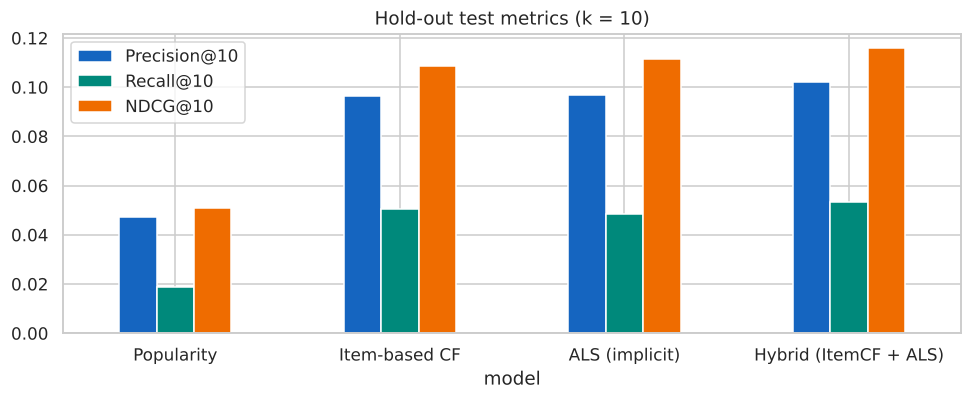

Best Precision@10 = 0.102 (Hybrid (ItemCF + ALS)), 2.2x the popularity baseline


In [15]:
def build_models():
    return [Popularity(), ItemCF(best_cf_n), ALS(**best_als),
            Hybrid(ItemCF(best_cf_n), ALS(**best_als), w_itemcf=best_w)]

test_res = evaluate(build_models(), train, truth).set_index("model")
display(test_res.drop(columns="params").round(4))

ax = test_res[["Precision@10", "Recall@10", "NDCG@10"]].plot.bar(figsize=(9, 3.8), rot=0,
                                                                  color=["#1565C0", "#00897B", "#EF6C00"])
ax.set_title("Hold-out test metrics (k = 10)")
plt.tight_layout(); plt.show()

base = test_res.loc["Popularity", "Precision@10"]
best_name = test_res["Precision@10"].idxmax()
print(f"Best Precision@10 = {test_res['Precision@10'].max():.3f} ({best_name}), "
      f"{test_res['Precision@10'].max() / base:.1f}x the popularity baseline")

In [16]:
# Per-segment performance of the best model (uses the segments from section 5).
final_models = build_models()
best_model = final_models[int(test_res["Precision@10"].values.argmax())]
data_train = InteractionData(train)
best_model.fit(data_train)
users = list(truth)
recs = dict(zip(users, best_model.recommend(users)))

by_seg = pd.DataFrame([
    {"Segment": s, **ranking_metrics(recs, {u: truth[u] for u in g.index})}
    for s, g in rfm.loc[[u for u in users if u in rfm.index]].groupby("Segment")
]).set_index("Segment").reindex(SEG_ORDER)
display(by_seg[["users", "Precision@10", "Recall@10", "HitRate@10", "NDCG@10"]].round(3))

,users,Precision@10,Recall@10,HitRate@10,NDCG@10
Segment,,,,,
Champions,279,0.117,0.040,0.545,0.129
Loyal,820,0.123,0.055,0.568,0.138
New / Promising,266,0.055,0.061,0.372,0.073
At Risk,463,0.085,0.052,0.467,0.096
Lost,24,0.083,0.077,0.500,0.089


In [17]:
# Cold start: customers who first bought after the split. Compare popularity with random picks.
pop_list = Popularity().fit(InteractionData(train)).recommend([-1], TOP_K)[0]
rng = np.random.default_rng(RANDOM_STATE)
all_items = InteractionData(train).items
cold = pd.DataFrame({
    "Popularity": ranking_metrics({u: pop_list for u in cold_truth}, cold_truth),
    "Random": ranking_metrics({u: list(rng.choice(all_items, TOP_K, replace=False)) for u in cold_truth}, cold_truth),
}).T
display(cold.round(4))

,Precision@10,Recall@10,HitRate@10,NDCG@10,users
Popularity,0.0817,0.0344,0.4851,0.0902,973.0
Random,0.0095,0.0029,0.0894,0.0097,973.0


## 7. Retrain on all data and export

In [18]:
full_data = InteractionData(tx)
final = Hybrid(ItemCF(best_cf_n), ALS(**best_als), w_itemcf=best_w).fit(full_data)

all_users = list(full_data.users)
all_recs = final.recommend(all_users, TOP_K)
desc = tx.drop_duplicates("StockCode").set_index("StockCode")["Description"]
rec_rows = [
    {"CustomerID": int(u), "rank": r, "StockCode": it, "Description": desc.get(it, it),
     "Segment": rfm["Segment"].get(u)}
    for u, recs_u in zip(all_users, all_recs) for r, it in enumerate(recs_u, 1)
]
recs_df = pd.DataFrame(rec_rows)
recs_df.to_csv(OUT / "customer_recommendations.csv", index=False)

popular = Popularity().fit(full_data).recommend([-1], TOP_K)[0]
(OUT / "cold_start_top10.json").write_text(json.dumps(
    [{"StockCode": c, "Description": desc.get(c, c)} for c in popular], indent=2))

joblib.dump({"itemcf_neighbours": best_cf_n, "als": best_als, "w_itemcf": best_w,
             "users": full_data.users, "items": full_data.items}, OUT / "recommender_config.joblib")

metrics = {
    "split_date": RECO_SPLIT_DATE,
    "best_params": {"itemcf_neighbours": best_cf_n, "als": best_als, "hybrid_w_itemcf": best_w},
    "segmentation": {"k": N_SEGMENTS, "silhouette": float(silhouette_score(X, kmeans.labels_)),
                     "segments": summary["customers"].to_dict()},
    "test": test_res.drop(columns="params").reset_index().to_dict(orient="records"),
}
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))

print("Exported to", OUT.resolve())
for p in sorted(OUT.iterdir()):
    print(f"  {p.name:32s} {p.stat().st_size / 1024:8.1f} KB")
recs_df.head(10)

Exported to /home/claude/notebooks/shopsegments_outputs
  cold_start_top10.json                 0.8 KB
  customer_recommendations.csv       2109.1 KB
  customer_segments.csv               179.9 KB
  metrics.json                          1.5 KB
  recommender_config.joblib            63.9 KB
  recommender_model.joblib           2131.5 KB
  segment_model.joblib                 19.1 KB
  segment_model.json                    0.8 KB
  segment_summary.csv                   1.4 KB


,CustomerID,rank,StockCode,Description,Segment
0,12346,1,22720,SET OF 3 CAKE TINS PANTRY DESIGN,At Risk
1,12346,2,22722,SET OF 6 SPICE TINS PANTRY DESIGN,At Risk
2,12346,3,22993,SET OF 4 PANTRY JELLY MOULDS,At Risk
3,12346,4,22666,RECIPE BOX PANTRY YELLOW DESIGN,At Risk
4,12346,5,23165,LARGE CERAMIC TOP STORAGE JAR,At Risk
5,12346,6,22961,JAM MAKING SET PRINTED,At Risk
6,12346,7,23307,SET OF 60 PANTRY DESIGN CAKE CASES,At Risk
7,12346,8,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,At Risk
8,12346,9,23167,SMALL CERAMIC TOP STORAGE JAR,At Risk
9,12346,10,22960,JAM MAKING SET WITH JARS,At Risk


## 8. Save the trained models

* `segment_model.joblib`: preprocessor + K-Means + cluster names (already saved in section 5, saved again here with its JSON twin).
* `segment_model.json`: the same model as plain numbers, so a deployed app can score a customer without scikit-learn.
* `recommender_model.joblib`: the fitted hybrid recommender as plain arrays (ItemCF similarity, ALS factors, interaction matrix). Loading it needs only numpy, scipy and joblib.

In [19]:
# Segmentation model: joblib + plain-JSON copy
joblib.dump(seg_model, OUT / "segment_model.joblib")
scaler = seg_model["preprocessor"].named_steps["scale"]
(OUT / "segment_model.json").write_text(json.dumps({
    "features": RFM,
    "transform": "log1p then standardise",
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "centroids": seg_model["kmeans"].cluster_centers_.tolist(),
    "names": [seg_model["names"][i] for i in range(N_SEGMENTS)],
}, indent=2))

# Recommender: fitted hybrid (trained on all data in section 7) stored as plain arrays
als_model = final.als.model
joblib.dump({
    "users": full_data.users, "items": full_data.items,
    "interactions": full_data.counts,                       # customer x product (sparse)
    "item_similarity": final.itemcf.sim,                    # pruned cosine similarity
    "als_user_factors": np.asarray(als_model.user_factors),
    "als_item_factors": np.asarray(als_model.item_factors),
    "params": {"itemcf_neighbours": best_cf_n, "als": best_als, "w_itemcf": best_w, "top_k": TOP_K},
}, OUT / "recommender_model.joblib", compress=3)

for p in sorted(OUT.iterdir()):
    print(f"{p.name:32s} {p.stat().st_size / 1024:9.1f} KB")

cold_start_top10.json                  0.8 KB
customer_recommendations.csv        2109.1 KB
customer_segments.csv                179.9 KB
metrics.json                           1.5 KB
recommender_config.joblib             63.9 KB
recommender_model.joblib            2131.5 KB
segment_model.joblib                  19.1 KB
segment_model.json                     0.8 KB
segment_summary.csv                    1.4 KB


In [20]:
# Quick check: reload the saved models and use them
sm = joblib.load(OUT / "segment_model.joblib")
print(predict_segment(example.drop(columns="Segment"), sm))

rm = joblib.load(OUT / "recommender_model.joblib")
uid = int(rm["users"][0]); ui = 0
scores = rm["als_user_factors"][ui] @ rm["als_item_factors"].T
scores[rm["interactions"][ui].indices] = -np.inf
print("ALS top-5 for customer", uid, [desc.get(rm["items"][i]) for i in np.argsort(-scores)[:5]])

cust_A    Champions
cust_B      At Risk
cust_C         Lost
Name: Segment, dtype: str


ALS top-5 for customer 12346 ['SET OF 3 CAKE TINS PANTRY DESIGN', 'SET OF 6 SPICE TINS PANTRY DESIGN', 'RECIPE BOX PANTRY YELLOW DESIGN', 'JAM MAKING SET PRINTED', 'JAM MAKING SET WITH JARS']


In [21]:
# Bundle everything into one zip and download it (Colab only)
import shutil
shutil.make_archive("shopsegments_outputs", "zip", OUT)
try:
    from google.colab import files
    files.download("shopsegments_outputs.zip")
except ImportError:
    print("Saved shopsegments_outputs.zip in the working directory")

Saved shopsegments_outputs.zip in the working directory


## 9. Check against the committed `src/` pipeline

The notebook is a standalone copy of `src/shopsegments`. This cell compares its results with `artifacts/metrics.json` (built by `scripts/build_artifacts.py`) so the two cannot drift apart silently. Skipped in Colab, where the artifacts are not present.


In [22]:
ref_path = next((p for p in (Path('../artifacts/metrics.json'), Path('artifacts/metrics.json')) if p.exists()), None)
if ref_path is None:
    print('artifacts/metrics.json not found (Colab run): comparison skipped')
else:
    ref = json.loads(ref_path.read_text())
    ref_test = {r['model']: r for r in ref['test']}
    rows = []
    for name, r in test_res.iterrows():
        for m in ('Precision@10', 'Recall@10', 'NDCG@10', 'Coverage'):
            rows.append({'model': name, 'metric': m, 'notebook': r[m], 'src pipeline': ref_test[name][m]})
    cmp = pd.DataFrame(rows); cmp['abs diff'] = (cmp['notebook'] - cmp['src pipeline']).abs()
    display(cmp.round(4))
    print('Same split date    :', RECO_SPLIT_DATE == ref['split_date'])
    print('Same hyper-params  :', {'itemcf_neighbours': best_cf_n, 'als': best_als, 'hybrid_w_itemcf': best_w} == ref['best_params'])
    print('Same segment sizes :', summary['customers'].to_dict() == pd.read_parquet(ref_path.parent / 'customers.parquet')['Segment'].value_counts().to_dict())
    print('Largest metric gap :', round(cmp['abs diff'].max(), 4))


,model,metric,notebook,src pipeline,abs diff
0,Popularity,Precision@10,0.0472,0.0472,0.0000
1,Popularity,Recall@10,0.0188,0.0188,0.0000
2,Popularity,NDCG@10,0.0507,0.0507,0.0000
3,Popularity,Coverage,0.0184,0.0184,0.0000
4,Item-based CF,Precision@10,0.0966,0.0966,0.0000
5,Item-based CF,Recall@10,0.0506,0.0506,0.0000
6,Item-based CF,NDCG@10,0.1087,0.1087,0.0000
7,Item-based CF,Coverage,0.3614,0.3600,0.0015
8,ALS (implicit),Precision@10,0.0969,0.0969,0.0000
9,ALS (implicit),Recall@10,0.0486,0.0486,0.0000


Same split date    : True
Same hyper-params  : True


Same segment sizes : True
Largest metric gap : 0.0015
